# 01 - Exploratory Data Analysis

**Goal of the project:** predict how many points (`PTS`) an NBA player scores in a game, using only what we know *before* tip-off.

This notebook follows the class workflow (California housing example): load the data, split off the test set first, then explore the **training set only**. No modeling, imputing, or feature changes happen here. Anything that looks off goes in the list at the bottom.

- **Data:** `data/processed/features.csv`, built by `src/build_features.py` (one row per player per game, 31 leak-free features).
- **Targets:** `PTS` (main) and `MIN` (target for stage 1 of the two-stage model).
- **Split (by season, never random):** train = 2023-24 + 2024-25, test = 2025-26. 2026-27 is the current season and is only for the live site, so it's dropped.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from build_features import FEATURES  # same feature list the models will use

FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

# chart style for the slides: one main color, light grid, no top/right box lines
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.labelcolor": INK, "axes.titleweight": "bold",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 11,
})
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 150)

In [2]:
df = pd.read_csv(ROOT / "data" / "processed" / "features.csv", parse_dates=["GAME_DATE"])
df = df[df["SEASON"] != "2026-27"]          # current season: live site only

# Create the test set FIRST (by season, not random), then never look at it again
train_set = df[df["SEASON"].isin(["2023-24", "2024-25"])].copy()
test_set = df[df["SEASON"] == "2025-26"]

print(f"train rows: {len(train_set):,}")
print(f"test rows:  {len(test_set):,}")
train_set.head()

train rows: 37,872
test rows:  19,522


,SEASON,GAME_ID,GAME_DATE,PLAYER_ID,PLAYER_NAME,TEAM,OPP,pts_season,pts_l3,pts_l5,pts_l10,min_season,min_l3,min_l5,min_l10,min_trend,fga_season,fga_l5,fg3a_season,fg3a_l5,fta_season,fta_l5,games_played,pts_prev_season,min_prev_season,HOME,rest_days,back_to_back,games_last_7,games_since_return,team_missing_min,opp_missing_min,opp_def_rtg,opp_pace,opp_pts_allowed,net_rtg_gap,pts_vs_opp,games_vs_opp,PTS,MIN
0,2023-24,22300076,2023-10-26,2544,LeBron James,LAL,PHX,21.0,21.0,21.0,21.0,29.0,29.0,29.0,29.0,0.0,16.0,16.0,4.0,4.0,1.0,1.0,1,28.909091,35.527273,1,1.0,0,1.0,10,0.0,37.0,98.671727,105.40,104.0,-15.972862,16.000000,1,21,35
1,2023-24,22300076,2023-10-26,201142,Kevin Durant,PHX,LAL,18.0,18.0,18.0,18.0,37.0,37.0,37.0,37.0,0.0,22.0,22.0,2.0,2.0,5.0,5.0,1,29.063830,35.595745,0,1.0,0,1.0,10,37.0,0.0,120.763142,98.54,119.0,15.972862,31.000000,1,39,39
2,2023-24,22300076,2023-10-26,201569,Eric Gordon,PHX,LAL,10.0,10.0,10.0,10.0,32.0,32.0,32.0,32.0,0.0,16.0,16.0,9.0,9.0,0.0,0.0,1,12.405797,28.463768,0,1.0,0,1.0,10,37.0,0.0,120.763142,98.54,119.0,15.972862,14.000000,2,15,30
3,2023-24,22300076,2023-10-26,203076,Anthony Davis,LAL,PHX,17.0,17.0,17.0,17.0,34.0,34.0,34.0,34.0,0.0,17.0,17.0,2.0,2.0,4.0,4.0,1,25.910714,34.035714,1,1.0,0,1.0,10,0.0,37.0,98.671727,105.40,104.0,-15.972862,26.000000,3,30,39
4,2023-24,22300076,2023-10-26,203994,Jusuf Nurkić,PHX,LAL,14.0,14.0,14.0,14.0,28.0,28.0,28.0,28.0,0.0,8.0,8.0,2.0,2.0,3.0,3.0,1,13.346154,26.750000,0,1.0,0,1.0,10,37.0,0.0,120.763142,98.54,119.0,15.972862,5.333333,3,4,28


## 1. Data types, ranges, and missing values

**What we're checking:** that every column has the right type, the ranges make sense (no negative minutes, no 200-point games), and which features have blanks.

In [3]:
train_set.info()

<class 'pandas.DataFrame'>
RangeIndex: 37872 entries, 0 to 37871
Data columns (total 40 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   SEASON              37872 non-null  str           
 1   GAME_ID             37872 non-null  int64         
 2   GAME_DATE           37872 non-null  datetime64[us]
 3   PLAYER_ID           37872 non-null  int64         
 4   PLAYER_NAME         37872 non-null  str           
 5   TEAM                37872 non-null  str           
 6   OPP                 37872 non-null  str           
 7   pts_season          37872 non-null  float64       
 8   pts_l3              37872 non-null  float64       
 9   pts_l5              37872 non-null  float64       
 10  pts_l10             37872 non-null  float64       
 11  min_season          37872 non-null  float64       
 12  min_l3              37872 non-null  float64       
 13  min_l5              37872 non-null  float64       
 14  m

In [4]:
train_set.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
GAME_ID,37872.0,22350976.260879,22300001.0,22300616.0,22400009.0,22400624.0,22401230.0,50003.530328
GAME_DATE,37872,2024-07-21 06:00:47.908745,2023-10-26 00:00:00,2024-01-19 00:00:00,2024-10-25 00:00:00,2025-01-19 00:00:00,2025-04-13 00:00:00,NaN
PLAYER_ID,37872.0,1334985.967654,2544.0,1626181.0,1629130.0,1630559.0,1642419.0,580383.046737
pts_season,37872.0,12.707963,0.0,7.846154,11.133974,16.609809,41.0,6.433139
pts_l3,37872.0,13.067376,0.0,7.666667,11.666667,17.666667,50.666667,7.328656
pts_l5,37872.0,13.040813,0.0,7.8,11.6,17.4,44.2,6.970009
pts_l10,37872.0,12.984651,0.0,7.9,11.5,17.1,41.0,6.685809
min_season,37872.0,26.229497,15.0,20.716903,26.350325,31.71648,44.0,6.321726
min_l3,37872.0,26.796477,1.0,21.333333,27.333333,32.666667,46.333333,7.297795
min_l5,37872.0,26.759296,2.4,21.4,27.4,32.4,44.6,6.970013


In [5]:
missing = train_set.isna().sum()
missing = pd.DataFrame({"missing": missing, "pct": (100 * missing / len(train_set)).round(1)})
missing[missing["missing"] > 0].sort_values("missing", ascending=False)

,missing,pct
pts_prev_season,3472,9.2
min_prev_season,3472,9.2
pts_vs_opp,2231,5.9
opp_def_rtg,16,0.0
opp_pace,16,0.0
opp_pts_allowed,16,0.0
net_rtg_gap,16,0.0


**Takeaway:** Everything is numeric except the ID columns (season, names, team abbreviations), and the ranges look right: minutes run from 5 (our filter) to 54 (overtime games), and points from 0 to 73. Only 6 features have any blanks:

- `pts_prev_season` / `min_prev_season` (~9%): players with no NBA games last season (mostly rookies). After adding 2022-23 as history, 2023-24 is no longer 100% blank.
- `pts_vs_opp` (~6%): first time this player has faced this opponent.
- `opp_def_rtg`, `opp_pace`, `opp_pts_allowed`, `net_rtg_gap` (16 rows, under 0.1%): the opponent's first game of the season, so no stats yet.

**For the model:** blanks are rare and have a real reason. `SimpleImputer(strategy="median")` inside the Pipeline (fit on train only) is enough.

## 2. Distribution of the targets: points and minutes

**What we're checking:** the shape of what we're predicting. The proposal guessed points would be right-skewed (most players score 5 to 20, a few score 40+).

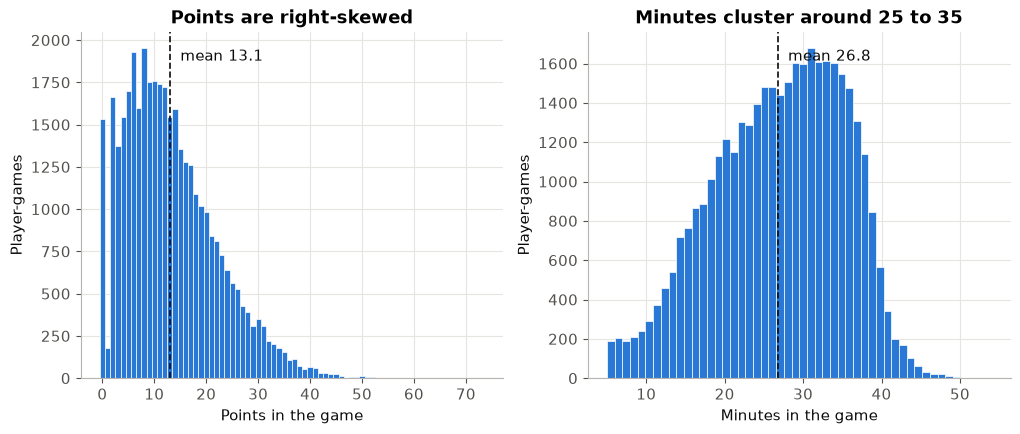

       count  mean  std  min   25%   50%   75%   max
PTS  37872.0  13.1  8.9  0.0   6.0  12.0  18.0  73.0
MIN  37872.0  26.8  8.5  5.0  21.0  28.0  33.0  54.0

skew: PTS 0.86, MIN -0.31
games with 0 points:   4.0%
games with 40+ points: 0.8%


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col, label in [(axes[0], "PTS", "Points in the game"), (axes[1], "MIN", "Minutes in the game")]:
    vals = train_set[col]
    bins = np.arange(0, vals.max() + 2) - 0.5 if col == "PTS" else 50
    ax.hist(vals, bins=bins, color=BLUE, edgecolor="white", linewidth=0.5)
    ax.axvline(vals.mean(), color=INK, linestyle="--", linewidth=1.2)
    ax.text(vals.mean(), ax.get_ylim()[1] * 0.95, f"  mean {vals.mean():.1f}", color=INK, va="top")
    ax.set_xlabel(label)
    ax.set_ylabel("Player-games")
axes[0].set_title("Points are right-skewed")
axes[1].set_title("Minutes cluster around 25 to 35")
plt.savefig(FIG_DIR / "01_pts_min_hist.png")
plt.show()

print(train_set[["PTS", "MIN"]].describe().round(1).T)
print(f"\nskew: PTS {train_set['PTS'].skew():.2f}, MIN {train_set['MIN'].skew():.2f}")
print(f"games with 0 points:   {(train_set['PTS'] == 0).mean():.1%}")
print(f"games with 40+ points: {(train_set['PTS'] >= 40).mean():.1%}")

**Takeaway:** The proposal's guess was right. Points are right-skewed: the median is 12, the mean is 13.1, half of all games land between 6 and 18, and fewer than 1% of games hit 40+. Minutes are the opposite shape: bunched up around 25 to 35 with a tail toward short nights (foul trouble, blowouts, injuries).

**For the model:** The skew means a few huge games (like a 73-point night) will produce big misses no matter what. That's why MAE is the main metric: it treats a 30-point miss as 30, while RMSE squares it and lets a handful of outliers dominate. Minutes are much more predictable than points, which supports the two-stage idea.

## 3. Correlations with points (and with minutes)

**What we're checking:** which features line up most with `PTS`, and separately with `MIN` (the stage 1 target in the two-stage model). Same idea as `corr_matrix["median_house_value"].sort_values()` in the class example.

Note: `MIN` and `PTS` are both *results* of the game, not features. They're included in each other's lists only for reference.

In [7]:
corr_matrix = train_set[FEATURES + ["PTS", "MIN"]].corr()
corr_pts = corr_matrix["PTS"].drop("PTS").sort_values(ascending=False)
corr_min = corr_matrix["MIN"].drop("MIN").sort_values(ascending=False)
pd.DataFrame({"feature (vs PTS)": corr_pts.index, "corr with PTS": corr_pts.values.round(3),
              "feature (vs MIN)": corr_min.index, "corr with MIN": corr_min.values.round(3)})

,feature (vs PTS),corr with PTS,feature (vs MIN),corr with MIN
0,pts_season,0.674,min_l10,0.699
1,MIN,0.674,min_l5,0.699
2,pts_l10,0.672,min_l3,0.691
3,fga_season,0.667,PTS,0.674
4,fga_l5,0.659,min_season,0.664
5,pts_l5,0.654,fga_l5,0.593
6,pts_l3,0.630,pts_l10,0.584
7,pts_prev_season,0.627,pts_l5,0.577
8,fta_season,0.583,fga_season,0.574
9,pts_vs_opp,0.566,pts_season,0.567


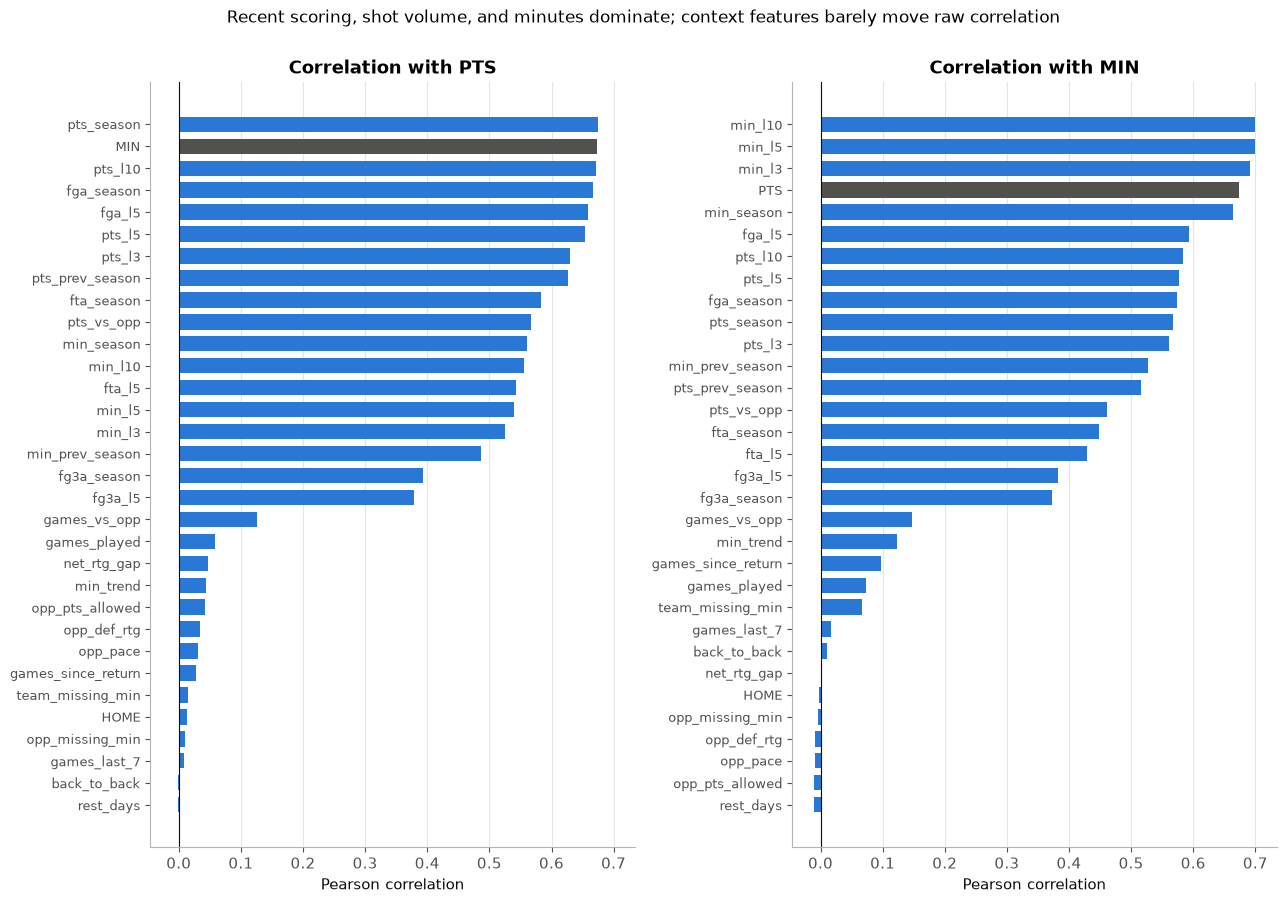

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 9), sharex=True)
for ax, corr, target in [(axes[0], corr_pts, "PTS"), (axes[1], corr_min, "MIN")]:
    c = corr.sort_values()
    colors = [MUTED if name in ("PTS", "MIN") else BLUE for name in c.index]
    ax.barh(c.index, c.values, color=colors, height=0.7)
    ax.axvline(0, color=INK, linewidth=0.8)
    ax.set_title(f"Correlation with {target}")
    ax.set_xlabel("Pearson correlation")
    ax.tick_params(axis="y", labelsize=9)
    ax.grid(axis="y", visible=False)
fig.suptitle("Recent scoring, shot volume, and minutes dominate; context features barely move raw correlation",
             fontsize=12, y=1.0)
plt.tight_layout()
plt.savefig(FIG_DIR / "02_correlations.png")
plt.show()

**Takeaway:**
- **Points:** the top of the list is the player's own track record: season scoring average (0.67), last-10 average (0.67), shot attempts (FGA, 0.66 to 0.67), last-5 (0.65), and last season's average (0.63). Actual minutes played (0.67) is right up there too, as the proposal expected.
- **Minutes:** recent minutes averages are the best predictors (`min_l5`, `min_l10` at 0.70). Minutes also correlate a bit with `min_trend` (0.12), `games_since_return` (0.10), and `team_missing_min` (0.07). Those are the "role is changing tonight" features, and they matter more for minutes than for points.
- **Context features** (home/away, rest, opponent defense, pace) are all near 0.

**For the model:** Two things to keep in mind:
1. Many top features say the same thing (season PPG, last-10 PPG, FGA all ≈ "how good a scorer is he"). That's fine for Ridge (regularization handles it) and for boosting, but it means feature importance will be split across them.
2. A near-zero correlation **doesn't** mean useless. Correlation only measures straight-line relationships across *all* players. A feature like `team_missing_min` should matter *relative to each player's normal* (section 7 shows it does). Let CV decide, not this table.

## 4. Scatter plots: minutes vs points, and last-5 average vs points

**What we're checking:** how tight these relationships really are. `alpha=0.1` like the class example, so dense areas look darker.

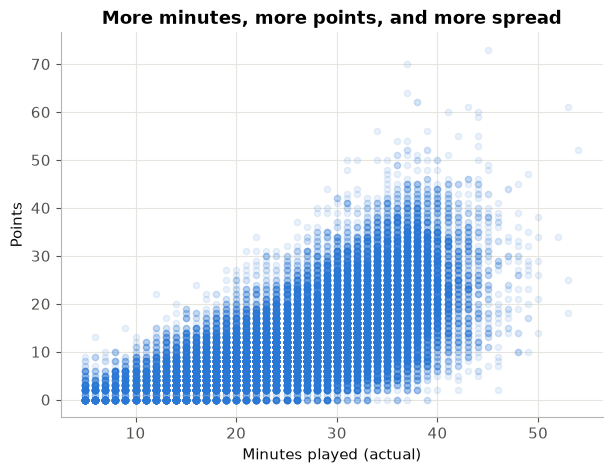

In [9]:
train_set.plot(kind="scatter", x="MIN", y="PTS", alpha=0.1, grid=True, color=BLUE, figsize=(7, 5))
plt.title("More minutes, more points, and more spread")
plt.xlabel("Minutes played (actual)")
plt.ylabel("Points")
plt.savefig(FIG_DIR / "03_scatter_min_pts.png")
plt.show()

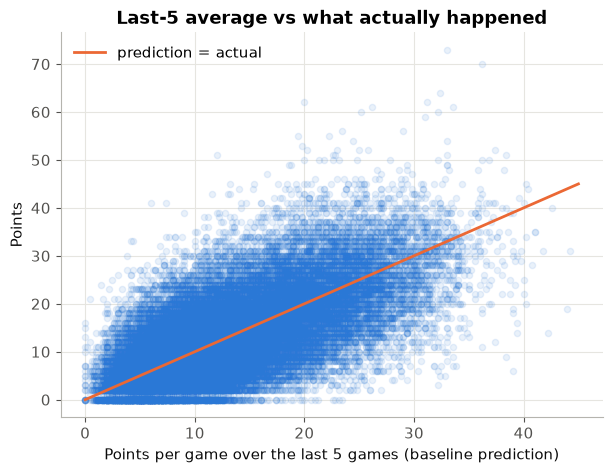

corr MIN vs PTS:    0.674
corr pts_l5 vs PTS: 0.654


In [10]:
ax = train_set.plot(kind="scatter", x="pts_l5", y="PTS", alpha=0.1, grid=True, color=BLUE, figsize=(7, 5))
lim = [0, 45]
ax.plot(lim, lim, color=ORANGE, linewidth=2, label="prediction = actual")
ax.legend(loc="upper left", frameon=False)
plt.title("Last-5 average vs what actually happened")
plt.xlabel("Points per game over the last 5 games (baseline prediction)")
plt.ylabel("Points")
plt.savefig(FIG_DIR / "04_scatter_l5_pts.png")
plt.show()

print("corr MIN vs PTS:   ", round(train_set["MIN"].corr(train_set["PTS"]), 3))
print("corr pts_l5 vs PTS:", round(train_set["pts_l5"].corr(train_set["PTS"]), 3))

**Takeaway:**
- **Minutes vs points** is a clear upward trend, but it fans out: a player with 10 minutes scores 0 to 10, while a player with 36 minutes can score anywhere from 0 to 50. More minutes means more points, but also more room for a hot or cold night.
- **Last-5 average vs points** follows the orange diagonal, but the cloud around it is wide. A player averaging 20 over his last 5 regularly scores anywhere from 10 to 30. The correlation is 0.65, so the last-5 average explains only about 43% of the variation (0.65² ≈ 0.43).

**For the model:** The baseline is in the right place but noisy. The model's job is to tighten that cloud a bit, mostly by getting the minutes part right. Since spread grows with minutes, the biggest absolute misses will be on high-minute starters.

## 5. Home vs away, and rest days

**What we're checking:** whether playing at home or on rest (vs a back-to-back) changes scoring. `rest_days = 0` means a back-to-back. Note that rest is the **team's** rest (days since the team's last game), capped at 7.

In [11]:
home = (train_set.groupby("HOME")["PTS"].agg(["mean", "count"])
        .rename(index={0: "away", 1: "home"}).round(2))
rest = train_set.groupby("rest_days")[["PTS", "MIN"]].agg(["mean", "count"]).round(2)
print(home, "\n")
print(rest)

       mean  count
HOME              
away  12.96  19013
home  13.21  18859 

             PTS           MIN       
            mean  count   mean  count
rest_days                            
0.0        13.06   6565  26.99   6565
1.0        13.08  23913  26.79  23913
2.0        13.12   5365  26.68   5365
3.0        13.25   1158  26.99   1158
4.0        12.88    333  26.36    333
5.0        10.76     38  23.13     38
6.0        11.16     43  25.53     43
7.0        12.95    457  26.57    457


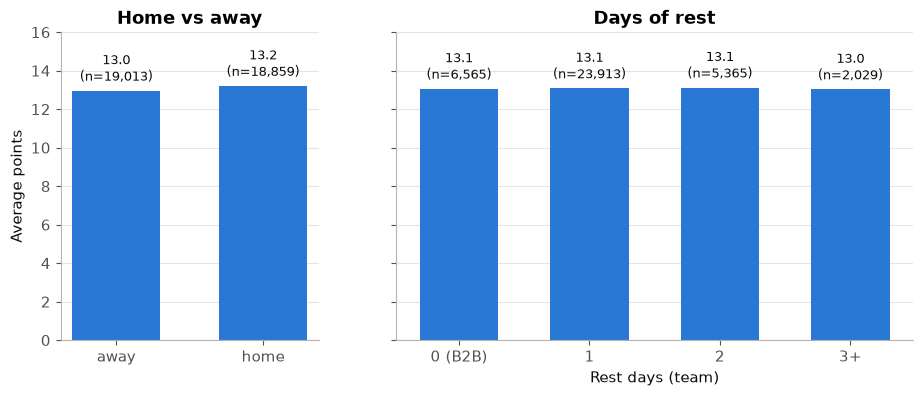

In [12]:
rest_bins = train_set["rest_days"].clip(upper=3).map({0: "0 (B2B)", 1: "1", 2: "2", 3: "3+"})
rest_avg = train_set.groupby(rest_bins)["PTS"].agg(["mean", "count"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True, gridspec_kw={"width_ratios": [2, 4]})
axes[0].bar(home.index, home["mean"], color=BLUE, width=0.6)
axes[1].bar(rest_avg.index, rest_avg["mean"], color=BLUE, width=0.6)
for ax, tbl in [(axes[0], home), (axes[1], rest_avg)]:
    for x, (m, n) in enumerate(zip(tbl["mean"], tbl["count"])):
        ax.text(x, m + 0.3, f"{m:.1f}\n(n={n:,})", ha="center", va="bottom", fontsize=9, color=INK)
    ax.grid(axis="x", visible=False)
axes[0].set_title("Home vs away")
axes[1].set_title("Days of rest")
axes[0].set_ylabel("Average points")
axes[1].set_xlabel("Rest days (team)")
axes[0].set_ylim(0, 16)
plt.savefig(FIG_DIR / "05_home_rest.png")
plt.show()

**Takeaway:** Basically no difference. Home players average 13.2 vs 13.0 away (+0.2 points), and back-to-backs (13.1) look the same as 1 or 2 days of rest. The 5- and 6-day groups are tiny (under 50 games each), so their lower averages are just noise.

One catch: the players who are most affected by back-to-backs (stars on load management) often just **sit out**, so they never show up in the back-to-back rows. That hides some of the fatigue effect.

**For the model:** Expect home/away and rest to add very little. Keep them in (they're cheap and the site needs home/away anyway) and let CV and feature importance decide.

## 6. Game-to-game swing: how low can MAE realistically go?

**What we're checking:** how much a player's scoring bounces around from night to night, even when nothing about his role changes. This sets a floor on how accurate *any* model can be. Then we score the baseline (last-5 average) on the training set.

Swing is measured per **player-season** (players with 20+ games in that season), so a role change between seasons doesn't inflate it.

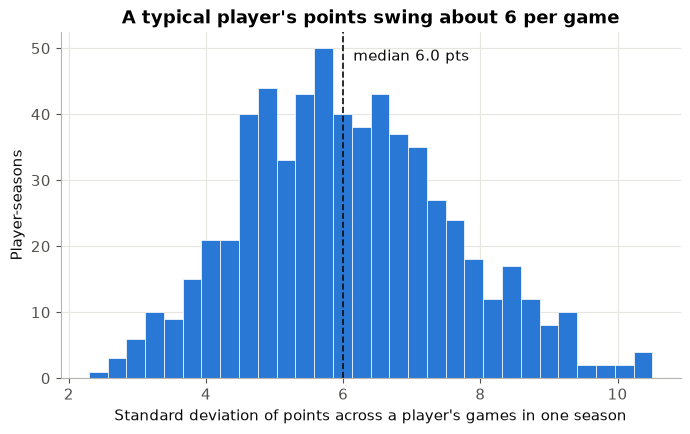

count    627.00
mean       6.08
std        1.52
min        2.29
25%        4.96
50%        6.00
75%        7.07
max       10.51
Name: std, dtype: float64

median swing as % of the player's average: 53%


In [13]:
swing = (train_set.groupby(["PLAYER_ID", "SEASON"])["PTS"]
         .agg(["std", "mean", "count"]).query("count >= 20"))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(swing["std"], bins=30, color=BLUE, edgecolor="white", linewidth=0.5)
ax.axvline(swing["std"].median(), color=INK, linestyle="--", linewidth=1.2)
ax.text(swing["std"].median(), ax.get_ylim()[1] * 0.95, f"  median {swing['std'].median():.1f} pts",
        color=INK, va="top")
ax.set_title("A typical player's points swing about 6 per game")
ax.set_xlabel("Standard deviation of points across a player's games in one season")
ax.set_ylabel("Player-seasons")
plt.savefig(FIG_DIR / "06_player_swing.png")
plt.show()

print(swing["std"].describe().round(2))
print(f"\nmedian swing as % of the player's average: {(swing['std'] / swing['mean']).median():.0%}")

In [14]:
def mae(y, pred):
    return (y - pred).abs().mean()

y = train_set["PTS"]
print(f"Baseline: last-5 average      MAE {mae(y, train_set['pts_l5']):.2f}   "
      f"RMSE {np.sqrt(((y - train_set['pts_l5']) ** 2).mean()):.2f}")
print(f"For comparison: last-10 avg   MAE {mae(y, train_set['pts_l10']):.2f}")
print(f"For comparison: season avg    MAE {mae(y, train_set['pts_season']):.2f}")

# "Cheating" reference: predict each player's median for the WHOLE season (uses future games,
# so not a real model). It shows the error left over from pure night-to-night noise.
oracle = train_set.groupby(["PLAYER_ID", "SEASON"])["PTS"].transform("median")
print(f"\nNoise floor (player's full-season median, uses future games): MAE {mae(y, oracle):.2f}")

Baseline: last-5 average      MAE 5.26   RMSE 6.80
For comparison: last-10 avg   MAE 5.11
For comparison: season avg    MAE 5.08

Noise floor (player's full-season median, uses future games): MAE 4.83


**Takeaway:**
- The typical player's points swing by about **6 points** (one standard deviation) from game to game, which is roughly **half his average**. A 12-point scorer routinely puts up 6 one night and 18 the next for no visible reason.
- The **baseline** (last-5 average) is off by **5.26 points** per game on the training set (RMSE 6.80).
- Surprise: the plain **season average** (5.08) and **last-10 average** (5.11) both beat last-5. Five games is so few that one hot or cold night moves the average a lot.
- Even a "cheating" prediction that knows each player's median for the *whole* season (including future games) is still off by about **4.8 points**. That's pure night-to-night noise.

**What this means for the model:** Realistically, MAE can't go much below ~4.8, since that's the noise floor for a fixed per-player guess. Game-specific info (tonight's minutes, who's out) can push a little under it, but not a lot. So **a good result looks like ~4.9 to 5.0**, which is a 5 to 7% improvement on the baseline. A model claiming something like 3.5 would almost certainly be leaking future information.

Also: since season average already beats last-5, the models need to beat **both**. Beating last-5 alone is too easy a bar to brag about.

## 7. Sanity checks on the features we added beyond the proposal

The proposal didn't list `team_missing_min`, `games_since_return`, `pts_prev_season`, or `games_vs_opp` in this exact form, so let's make sure each one behaves the way basketball sense says it should. Plus: how noisy is `opp_def_rtg` early in the season?

To see effects *relative to each player's normal*, we compare against his pre-game season average:
- `pts_vs_usual` = PTS - pts_season (scored more or less than his normal)
- `min_vs_usual` = MIN - min_season (played more or less than his normal)

These are temporary columns on a copy, only for this section (not features).

In [15]:
eda = train_set.copy()
eda["pts_vs_usual"] = eda["PTS"] - eda["pts_season"]
eda["min_vs_usual"] = eda["MIN"] - eda["min_season"]
print(f"overall average: pts_vs_usual {eda['pts_vs_usual'].mean():+.2f}, "
      f"min_vs_usual {eda['min_vs_usual'].mean():+.2f}  (the reference level)")

overall average: pts_vs_usual +0.38, min_vs_usual +0.57  (the reference level)


### 7a. `team_missing_min`: usual rotation minutes missing tonight

Expectation: when teammates are out, the remaining players play more and score more.

In [16]:
print(eda["team_missing_min"].describe().round(1))
print(f"games with nobody missing: {(eda['team_missing_min'] == 0).mean():.0%}")

eda["missing_bin"] = pd.cut(eda["team_missing_min"], [-1, 0, 30, 60, 100, 1000],
                            labels=["0", "1-30", "31-60", "61-100", "100+"])
by_missing = eda.groupby("missing_bin", observed=True)[["pts_vs_usual", "min_vs_usual"]].mean().round(2)
by_missing["games"] = eda["missing_bin"].value_counts()
by_missing

count    37872.0
mean        44.9
std         38.2
min          0.0
25%         17.1
50%         36.1
75%         66.1
max        225.4
Name: team_missing_min, dtype: float64
games with nobody missing: 20%


,pts_vs_usual,min_vs_usual,games
missing_bin,,,
0,-0.60,-1.12,7582
1-30,-0.32,-0.46,7618
31-60,0.31,0.53,11257
61-100,1.16,1.80,8065
100+,2.50,3.91,3350


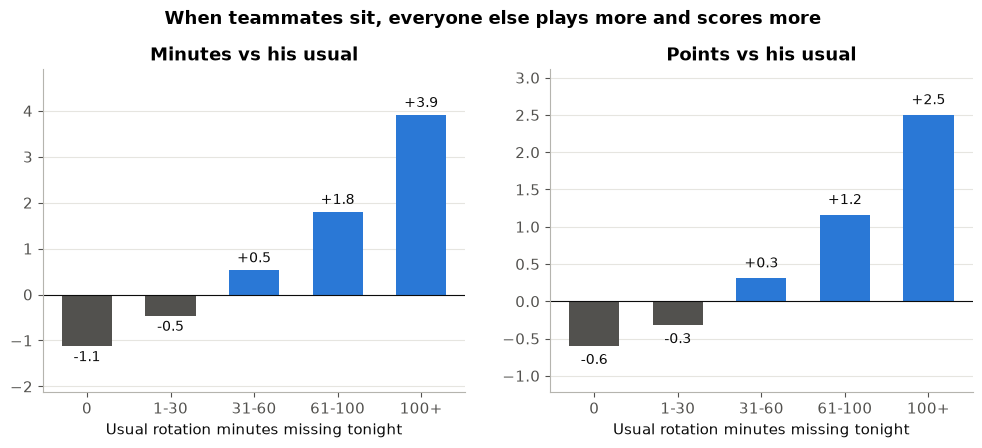

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharex=True)
for ax, col, label in [(axes[0], "min_vs_usual", "Minutes vs his usual"),
                       (axes[1], "pts_vs_usual", "Points vs his usual")]:
    vals = by_missing[col]
    ax.bar(vals.index.astype(str), vals.values, color=[MUTED if v < 0 else BLUE for v in vals], width=0.6)
    ax.axhline(0, color=INK, linewidth=0.8)
    for x, v in enumerate(vals):
        ax.text(x, v + (0.1 if v >= 0 else -0.1), f"{v:+.1f}", ha="center",
                va="bottom" if v >= 0 else "top", fontsize=10, color=INK)
    ax.margins(y=0.2)
    ax.set_title(label)
    ax.set_xlabel("Usual rotation minutes missing tonight")
    ax.grid(axis="x", visible=False)
fig.suptitle("When teammates sit, everyone else plays more and scores more", fontweight="bold", y=1.02)
plt.savefig(FIG_DIR / "07_team_missing_min.png")
plt.show()

**Takeaway:** It works exactly like it should, and the effect climbs steadily. With nobody missing, players play 1.1 minutes *below* their season average. With 100+ rotation minutes missing (roughly three regulars out), they play **3.9 minutes above** it and score **2.5 points above** it. That's a swing of about **5 minutes and 3 points** between a full-strength night and a short-handed one. 20% of games have nobody missing; the median game has about 36 rotation minutes missing.

(Small detail: across *all* rows, players average +0.6 minutes and +0.4 points vs their season average, because our filters drop games under 5 minutes. So the honest comparison is between the bars, not against zero.)

Its raw correlation with PTS was only 0.015 (section 3) because it's a *relative* effect: a missing teammate bumps a 5-point scorer by 1 and a 25-point scorer by 4, and correlation across all players washes that out.

**For the model:** Keep it. It's also exactly what powers the site's "who's out tonight" checklist. Gradient boosting can pick up the "relative to his normal" effect on its own; Ridge may need help (for example an interaction with minutes), which we can test in the modeling notebook.

### 7b. `games_since_return`: games since coming back from an absence

0 = first game back, capped at 10 ("settled in", also used for players who never missed a game).

In [18]:
by_return = eda.groupby("games_since_return")[["pts_vs_usual", "min_vs_usual"]].mean().round(2)
by_return["games"] = eda["games_since_return"].value_counts()
by_return

,pts_vs_usual,min_vs_usual,games
games_since_return,,,
0,-0.33,-1.21,2696
1,0.09,-0.09,2276
2,0.26,0.22,2005
3,0.51,0.78,1715
4,0.49,1.00,1537
5,0.34,0.61,1383
6,0.26,1.07,1239
7,0.78,1.11,1120
8,0.32,1.25,1034


**Takeaway:** The first game back is the outlier: 1.2 minutes *below* his season average, vs about +0.7 for a settled-in player, so roughly **2 fewer minutes** and **0.8 fewer points** than a normal night (minutes restrictions, rust). By game 2 or 3 it's back to normal. The capped "10" group is the big majority (~58% of rows).

**For the model:** Small but real effect, concentrated in one value (0). Mostly useful for the minutes model. Trees can handle the "only game 0 matters" shape directly.

### 7c. `pts_prev_season`: last season's scoring average

Now that 2022-23 is loaded as history, this should be missing only for players with no games last season (mostly rookies). Main question: does it help early in the season, when `pts_season` is based on just a game or two?

In [19]:
print("missing by season (%):")
print((eda.groupby("SEASON")["pts_prev_season"].apply(lambda s: s.isna().mean()) * 100).round(1))

has_prev = eda.dropna(subset=["pts_prev_season"]).copy()
has_prev["games_played_bin"] = pd.cut(has_prev["games_played"], [0, 2, 5, 10, 20, 100], right=False,
                                      labels=["1-2", "3-5", "6-10", "11-20", "21+"])
early = has_prev.groupby("games_played_bin", observed=True).apply(
    lambda d: pd.Series({"MAE last season avg": mae(d["PTS"], d["pts_prev_season"]),
                         "MAE this season avg": mae(d["PTS"], d["pts_season"]),
                         "games": len(d)}), include_groups=False).round(2)
early

missing by season (%):
SEASON
2023-24     8.1
2024-25    10.2
Name: pts_prev_season, dtype: float64


,MAE last season avg,MAE this season avg,games
games_played_bin,,,
1-2,5.13,6.16,534.0
3-5,5.20,5.29,1619.0
6-10,5.18,4.98,2783.0
11-20,5.34,4.96,5640.0
21+,5.62,5.14,23824.0


**Takeaway:** Missing is down to 8 to 10% in both training seasons, which now matches the test season (~10%). That was the point of the 2022-23 fix: train and test now look alike.

And it earns its spot: in a player's first 1 to 2 games, last season's average is a **much better guess** (MAE ~5.1) than this season's (~6.2, based on one or two games). By games 6 to 10, this season's average takes over.

**For the model:** Keep it. It covers the early-season gap, which also matters for the live site (we're only ~2 weeks into 2026-27).

### 7d. `games_vs_opp` and `pts_vs_opp`: matchup history

The proposal said to test this, not assume it. A player only sees each team 2 to 4 times a season.

In [20]:
print("earlier games vs this opponent (all seasons incl. 2022-23 history):")
print(eda["games_vs_opp"].clip(upper=10).value_counts().sort_index().rename(index={10: "10+"}))

# Does "he scores more than usual vs this team" carry over to tonight?
m = eda.dropna(subset=["pts_vs_opp"])
edge = m["pts_vs_opp"] - m["pts_season"]           # his history vs this team, relative to his normal
print(f"\ncorr(pts_vs_opp, PTS)                          = {m['pts_vs_opp'].corr(m['PTS']):.3f}")
print(f"corr(history edge vs opp, tonight vs his usual) = {edge.corr(m['pts_vs_usual']):.3f}")

earlier games vs this opponent (all seasons incl. 2022-23 history):
games_vs_opp
0      2231
1      3650
2      6027
3      6382
4      6113
5      4737
6      3238
7      2369
8      1582
9       965
10+     578
Name: count, dtype: int64

corr(pts_vs_opp, PTS)                          = 0.566
corr(history edge vs opp, tonight vs his usual) = 0.080


**Takeaway:** `pts_vs_opp` correlates 0.57 with points, but that's misleading: it's mostly just another measure of "how good a scorer is he." The real question is whether a player who *usually beats his average* against this team does so again tonight. That correlation is only **0.08**: a tiny signal, mostly noise. Most rows are based on just 1 to 5 earlier games.

**For the model:** As the proposal predicted, matchup history is weak. Leave it in for now and let CV and feature importance decide. If it doesn't help, dropping it is a fine slide ("I tested the matchup myth").

### 7e. How noisy is `opp_def_rtg` early in the season?

Opponent defensive rating is season-to-date, so in week 1 it's based on 1 to 3 games.

      std    min    max
week                   
1     8.2   82.4  143.8
2     5.1   89.0  118.4
3     4.6   94.0  118.1
4     4.0   98.4  118.8
5     4.1  100.4  118.5
6     3.9  100.6  118.8
7     4.0  101.0  119.1
8     3.8  101.3  119.7
9     3.9  100.8  119.6
10    3.9  100.7  119.5
...
weeks 10+: average std 3.3


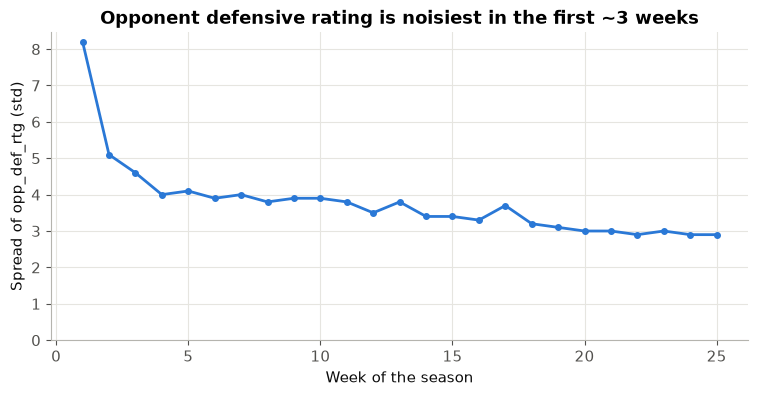

In [21]:
season_start = eda.groupby("SEASON")["GAME_DATE"].transform("min")
eda["week"] = (eda["GAME_DATE"] - season_start).dt.days // 7 + 1
by_week = eda.groupby("week")["opp_def_rtg"].agg(["std", "min", "max"]).round(1)
print(by_week.head(10))
print("...")
print(f"weeks 10+: average std {by_week.loc[10:, 'std'].mean():.1f}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(by_week.index, by_week["std"], color=BLUE, linewidth=2, marker="o", markersize=4)
ax.set_title("Opponent defensive rating is noisiest in the first ~3 weeks")
ax.set_xlabel("Week of the season")
ax.set_ylabel("Spread of opp_def_rtg (std)")
ax.set_ylim(0, None)
plt.savefig(FIG_DIR / "08_opp_def_rtg_by_week.png")
plt.show()

**Takeaway:** In week 1 the spread of opponent defensive rating is about **2.5x** what it is from week 10 on (std 8.2 vs 3.3), with values as extreme as 82 and 144 (over a full season, real NBA defenses fall roughly between 105 and 120). It drops fast over the first ~3 weeks, then keeps tightening slowly all season.

**For the model:** Early-season opponent stats are mostly noise. Trees may learn to ignore them; Ridge will take them at face value. The fix noted in CLAUDE.md (blend in last season's rating for the first few weeks) is a candidate, but only if the opponent features turn out to matter at all. That matters more for the live site, since 2026-27 is in week 3 right now.

## Things to look into (not fixed here)

1. **The baseline is weak.** Season average (5.08) and last-10 (5.11) beat the last-5 baseline (5.26) on train. Report the season average next to last-5 in the model comparison, so "beats the baseline" means something.
2. **Early-season opponent stats are noisy** (7e). Possible fix: blend in last season's opponent rating for the first ~10 games. Test only if opponent features show up in feature importance.
3. **Effects are relative to each player's normal** (`team_missing_min`, `games_since_return`). Raw correlation hides them. Ridge may need an interaction or a "vs usual" formulation; boosting should catch it on its own.
4. **Rest days are team rest, not player rest.** A player returning from injury has "1 day of rest" by this measure. `games_since_return` partly covers that. The 5 to 7 day groups are small and mix the All-Star break with season openers.
5. **Lots of overlapping features** (season PPG, L10 PPG, FGA season, FGA L5 all ~0.66 with PTS). Fine for Ridge and HGB, but feature importance will be split among them, so read importance by group.
6. **Matchup history is a weak signal** (0.08). Candidate to drop if CV agrees.
7. **Huge games** (40+ points, <1% of rows) will be the biggest misses for any model. MAE is the right main metric for that reason.

## Key findings

- **Points are right-skewed**: median 12, mean 13.1, half of games between 6 and 18, under 1% hit 40+.
- **A player's own track record is the strongest signal**: season PPG, last-10 PPG, and shot attempts all correlate ~0.67 with points. For minutes, recent minutes averages lead (~0.70).
- **Scoring is noisy**: a typical player's points swing ~6 per game (about half his average). Even knowing his full-season median, you're off by ~4.8 per game. That's the realistic floor.
- **Baseline to beat**: last-5 average MAE 5.26 on train. The season average already does better (5.08), so a good model lands around 4.9 to 5.0.
- **Missing teammates matter**: going from nobody out to 100+ rotation minutes out, the remaining players play ~5 more minutes and score ~3 more points. That's the site's "who's out" toggle, backed by data.
- **Home/away and rest barely matter**: +0.2 points at home, no back-to-back effect (13.1 either way).
- **Matchup history is mostly a myth**: a player's past edge against a team barely carries over (correlation 0.08).
- **Early-season opponent stats are noisy**: opponent defensive rating spreads ~2.5x wider in week 1 than from week 10 on.